In [1]:
import iris
import warnings

from iris.warnings import (IrisLoadWarning, IrisCfNonSpanningVarWarning, IrisCfMissingVarWarning)

warnings.filterwarnings("ignore", category=IrisLoadWarning)
warnings.filterwarnings("ignore", category=IrisCfNonSpanningVarWarning)
warnings.filterwarnings("ignore", category=IrisCfMissingVarWarning)

import numpy as np
import sys
import subprocess

# Matplotlib imports
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import TwoSlopeNorm

# Scipy imports
import scipy
from scipy.signal import savgol_filter
from scipy.interpolate import RegularGridInterpolator

# Iris imports
from iris.analysis import trajectory
from iris.analysis.cartography import rotate_pole


from pathlib import Path
sys.path.append("/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration")

import momentum_fluxes.momentum_flux_funcs as tx

orog_data_path_base = "/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/raso_through_model_output/"

# Output file where the orography lives
data_path_orog = "orography_u-eb392_run1_0p3km.nc"

# Original model run filepath. Used for orography inside function to calculate vertical levels
original_model_data_path = "/gws/ssde/j25b/team_x/sidmba/u-eb392_run1/0p3km_v3/w_ALPS_0p3km_ERA5_BAS_MetUM_v3_2s_20250224T1200Z.nc"

sonde_ids = []

# data_path_base = "/gws/ssde/j25b/team_x/TEAMx_FLOW/tbanyard/data/radiosondes/sterzing/202502"
data_path_base = "/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/momentum_fluxes/iop_17_18/" 

raw_sonde_list = sorted(Path(f"{data_path_base}/iop_17_18_raw_sonde_data").glob("*.nc"))
coarse_sonde_list = sorted(Path(f"{data_path_base}/iop_17_18_coarse_sonde_data").glob("*.nc"))
model_sonde_list = sorted(Path(f"{data_path_base}/iop_17_18_model_sonde_data").glob("*.nc"))

index = 3

# %%
# Paths for the sonde and model data

sonde_id = raw_sonde_list[index].stem[13:21]

raw_data_path = raw_sonde_list[index]
coarse_data_path = coarse_sonde_list[index]
model_data_path = model_sonde_list[index]

data_path_orog = "orography_u-eb392_run1_0p3km.nc"

original_model_data_path_4 = "/gws/ssde/j25b/team_x/sidmba/u-eb392_run1/0p3km_v3/w_ALPS_0p3km_ERA5_BAS_MetUM_v3_2s_20250224T1200Z.nc"




In [2]:

# %%
# Import in some data to see what it looks like
plot_title_affix = f"{sonde_id}"
cubelist_s_path = f"{coarse_data_path}"
cubelist_m_path = f"{model_data_path}"
cubelist_r_path = f"{raw_data_path}"

cubelist_mo_path = f"{original_model_data_path}"
orog_cube_path = f"{data_path_base}/{data_path_orog}"

cubelist_s = iris.load(cubelist_s_path)
cubelist_m = iris.load(cubelist_m_path)
cubelist_mo = iris.load(cubelist_mo_path)
orog_cube = iris.load(orog_cube_path)

#cubelist_m

# %%
# First, extract the relevant cubes 
u_s_wind_nonans, u_s_wind_mask = tx.nonans_cubedata(cubelist_s_path, "eastward_wind")
v_s_wind_nonans, v_s_wind_mask = tx.nonans_cubedata(cubelist_s_path, "northward_wind")
T_s_nonans, T_s_mask = tx.nonans_cubedata(cubelist_s_path, "air_temperature")
Theta_s_nonans, Theta_s_mask = tx.nonans_cubedata(cubelist_s_path, "air_potential_temperature")
pressure_s_nonans, pressure_s_mask = tx.nonans_cubedata(cubelist_s_path, "air_pressure")

u_m_wind_nonans, u_m_wind_mask = tx.nonans_cubedata(cubelist_m_path, "eastward_wind")
v_m_wind_nonans, v_m_wind_mask = tx.nonans_cubedata(cubelist_m_path, "northward_wind")
T_m_nonans, T_m_mask = tx.nonans_cubedata(cubelist_m_path, "air_temperature")
Theta_m_nonans, Theta_m_mask = tx.nonans_cubedata(cubelist_m_path, "air_potential_temperature")
pressure_m_nonans, pressure_m_mask = tx.nonans_cubedata(cubelist_m_path, "air_pressure")

u_r_wind_nonans, u_r_wind_mask = tx.nonans_cubedata(cubelist_r_path, "eastward_wind")
v_r_wind_nonans, v_r_wind_mask = tx.nonans_cubedata(cubelist_r_path, "northward_wind")
T_r_nonans, T_r_mask = tx.nonans_cubedata(cubelist_r_path, "air_temperature")
Theta_r_nonans, Theta_r_mask = tx.nonans_cubedata(cubelist_r_path, "air_potential_temperature")
pressure_r_nonans, pressure_r_mask = tx.nonans_cubedata(cubelist_r_path, "air_pressure")
alt_nonans, alt_mask = tx.nonans_cubedata(cubelist_r_path, "altitude")
time_nonans, time_mask = tx.nonans_cubedata(cubelist_r_path, "Elapsed Time")


# Extract the vert_levels to plot as background
cross_heights = tx.vert_levels_for_sonde(sonde_data_path=cubelist_s_path, 
                                  model_sonde_data_path=cubelist_m_path, 
                                  model_data_path=cubelist_mo_path, 
                                  model_orog_path=orog_cube_path)





In [3]:
# %%
# Now, fit a polynomial to the u and T data and find coeffs
p_deg = 4
u_s_wind_coeffs = np.polynomial.Polynomial.fit(alt_nonans, u_s_wind_nonans, p_deg)
v_s_wind_coeffs = np.polynomial.Polynomial.fit(alt_nonans, v_s_wind_nonans, p_deg)
T_s_coeffs = np.polynomial.Polynomial.fit(alt_nonans, T_s_nonans, p_deg)
pressure_s_coeffs = np.polynomial.Polynomial.fit(alt_nonans, pressure_s_nonans, p_deg)
Theta_s_coeffs = np.polynomial.Polynomial.fit(alt_nonans, Theta_s_nonans, p_deg+1)

u_m_wind_coeffs = np.polynomial.Polynomial.fit(alt_nonans, u_m_wind_nonans, p_deg)
v_m_wind_coeffs = np.polynomial.Polynomial.fit(alt_nonans, v_m_wind_nonans, p_deg)
T_m_coeffs = np.polynomial.Polynomial.fit(alt_nonans, T_m_nonans, p_deg)
pressure_m_coeffs = np.polynomial.Polynomial.fit(alt_nonans, pressure_m_nonans, p_deg)
Theta_m_coeffs = np.polynomial.Polynomial.fit(alt_nonans, Theta_m_nonans, p_deg+1)

u_r_wind_coeffs = np.polynomial.Polynomial.fit(alt_nonans, u_r_wind_nonans, p_deg)
v_r_wind_coeffs = np.polynomial.Polynomial.fit(alt_nonans, v_r_wind_nonans, p_deg)
T_r_coeffs = np.polynomial.Polynomial.fit(alt_nonans, T_r_nonans, p_deg)
pressure_r_coeffs = np.polynomial.Polynomial.fit(alt_nonans, pressure_r_nonans, p_deg)
Theta_r_coeffs = np.polynomial.Polynomial.fit(alt_nonans, Theta_r_nonans, p_deg+1)

# Find the mean profiles using the calculated coefficients
u_s_wind_mean = u_s_wind_coeffs(alt_nonans)
v_s_wind_mean = v_s_wind_coeffs(alt_nonans)
T_s_mean = T_s_coeffs(alt_nonans)
pressure_s_mean = pressure_s_coeffs(alt_nonans)
Theta_s_mean = Theta_s_coeffs(alt_nonans)

u_m_wind_mean = u_m_wind_coeffs(alt_nonans)
v_m_wind_mean = v_m_wind_coeffs(alt_nonans)
T_m_mean = T_m_coeffs(alt_nonans)
pressure_m_mean = pressure_m_coeffs(alt_nonans)
Theta_m_mean = Theta_m_coeffs(alt_nonans)

u_r_wind_mean = u_r_wind_coeffs(alt_nonans)
v_r_wind_mean = v_r_wind_coeffs(alt_nonans)
T_r_mean = T_r_coeffs(alt_nonans)
pressure_r_mean = pressure_r_coeffs(alt_nonans)
Theta_r_mean = Theta_r_coeffs(alt_nonans)

# Find the perturbations using raw - mean
u_s_wind_prime = u_s_wind_nonans - u_s_wind_mean
v_s_wind_prime = v_s_wind_nonans - v_s_wind_mean
T_s_prime = T_s_nonans - T_s_mean
pressure_s_prime = pressure_s_nonans - pressure_s_mean
Theta_s_prime = Theta_s_nonans - Theta_s_mean

u_m_wind_prime = u_m_wind_nonans - u_m_wind_mean
v_m_wind_prime = v_m_wind_nonans - v_m_wind_mean
T_m_prime = T_m_nonans - T_m_mean
pressure_m_prime = pressure_m_nonans - pressure_m_mean
Theta_m_prime = Theta_m_nonans - Theta_m_mean

u_r_wind_prime = u_r_wind_nonans - u_r_wind_mean
v_r_wind_prime = v_r_wind_nonans - v_r_wind_mean
T_r_prime = T_r_nonans - T_r_mean
pressure_r_prime = pressure_r_nonans - pressure_r_mean
Theta_r_prime = Theta_r_nonans - Theta_r_mean

# Normalise the Temperatures to find T prime hat
T_hat_s_prime = T_s_prime / T_s_mean
T_hat_m_prime = T_m_prime / T_m_mean
T_hat_r_prime = T_r_prime / T_r_mean





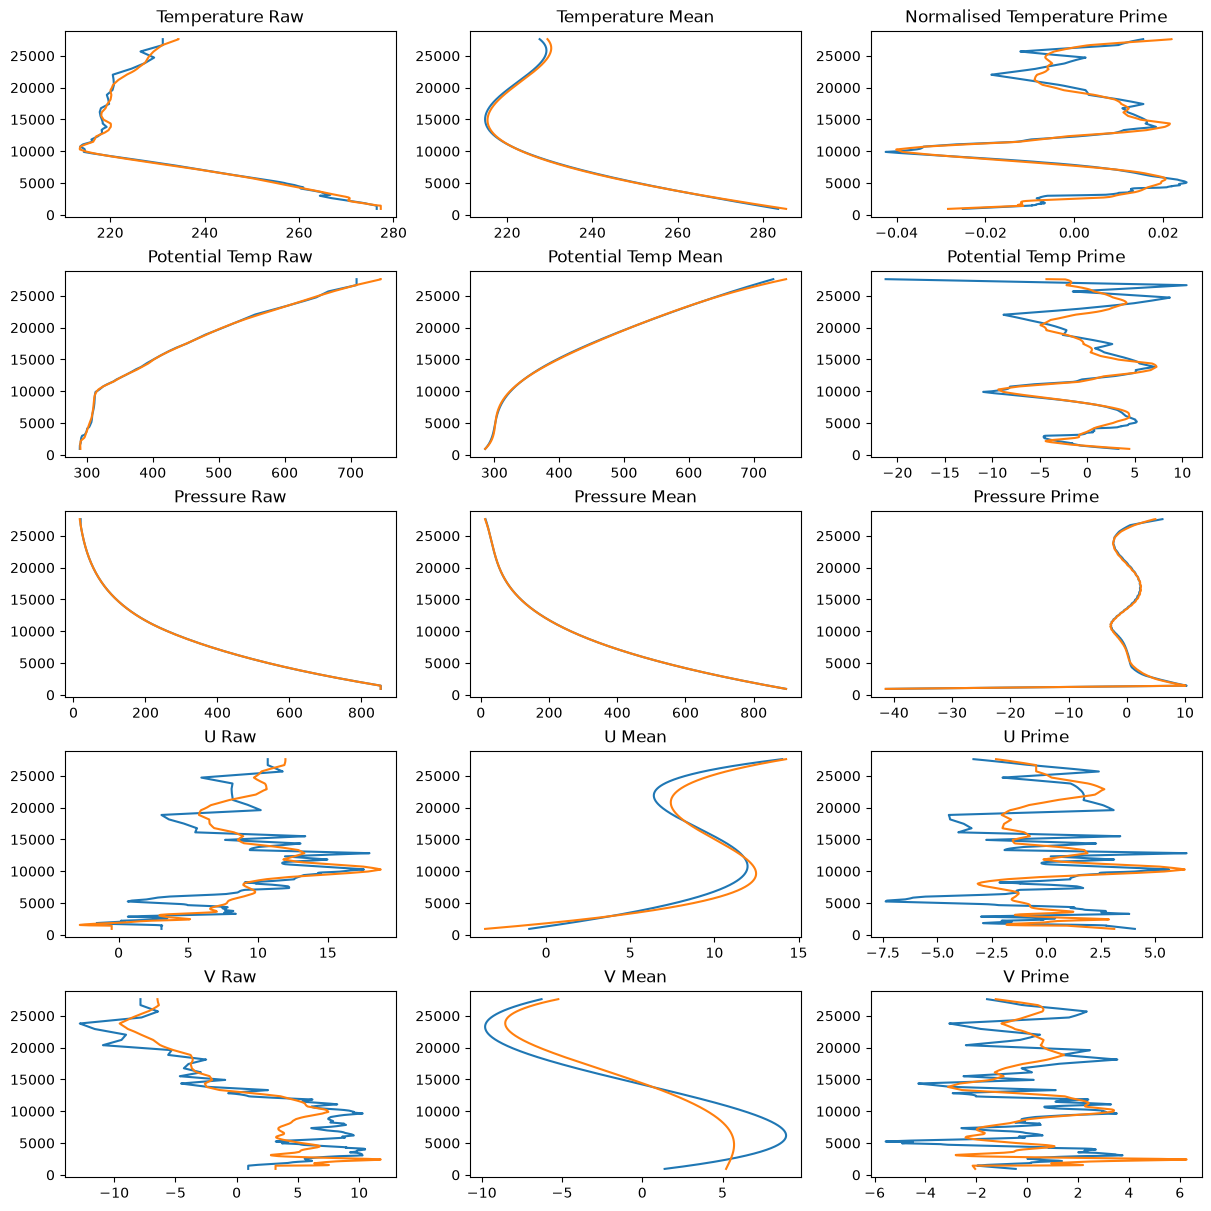

In [4]:
# %%
# Now plot the mean profiles against raw
fig = plt.figure(figsize=(12,12), layout="constrained")
ax = fig.subplots(5,3).flatten()

var_s_list = [T_s_nonans, T_s_mean, T_hat_s_prime, 
              Theta_s_nonans, Theta_s_mean, Theta_s_prime,
              pressure_s_nonans, pressure_s_mean, pressure_s_prime,
              u_s_wind_nonans, u_s_wind_mean, u_s_wind_prime, 
              v_s_wind_nonans, v_s_wind_mean, v_s_wind_prime]

var_m_list = [T_m_nonans, T_m_mean, T_hat_m_prime, 
              Theta_m_nonans, Theta_m_mean, Theta_m_prime,
              pressure_m_nonans, pressure_m_mean, pressure_m_prime,
              u_m_wind_nonans, u_m_wind_mean, u_m_wind_prime, 
              v_m_wind_nonans, v_m_wind_mean, v_m_wind_prime]

var_r_list = [T_r_nonans, T_r_mean, T_hat_r_prime, 
              Theta_r_nonans, Theta_r_mean, Theta_r_prime,
              pressure_r_nonans, pressure_r_mean, pressure_r_prime,
              u_r_wind_nonans, u_r_wind_mean, u_r_wind_prime, 
              v_r_wind_nonans, v_r_wind_mean, v_r_wind_prime]


title_list = ["Temperature Raw", "Temperature Mean", "Normalised Temperature Prime", 
              "Potential Temp Raw", "Potential Temp Mean", "Potential Temp Prime",
              "Pressure Raw", "Pressure Mean", "Pressure Prime",   
              "U Raw", "U Mean", "U Prime", 
              "V Raw", "V Mean", "V Prime"]

for i,j in enumerate(var_s_list):
    ax[i].plot(var_s_list[i], alt_nonans, color="C0")
    ax[i].plot(var_m_list[i], alt_nonans, color="C1")
    #ax[i].plot(var_r_list[i], alt_nonans, color="C2")
    ax[i].set_title(title_list[i])

plt.show()
plt.close()


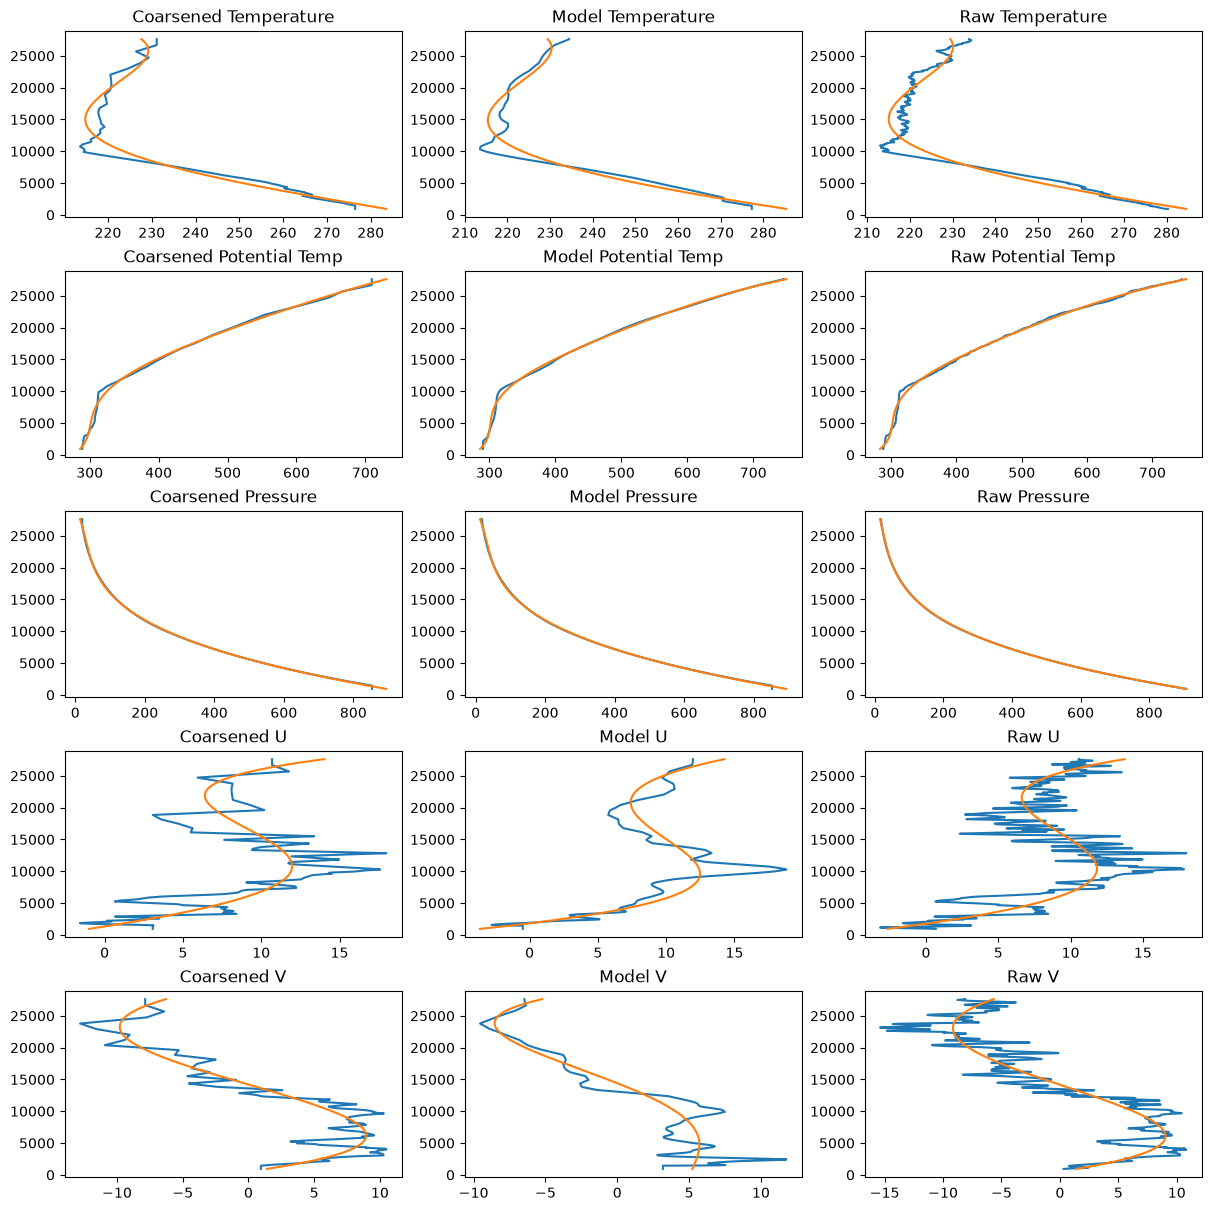

In [5]:
# %%
# Sanity check. What does the mean potential temperature profile look like against raw theta?

# What do the mean profiles look like against the raw profiles
fig = plt.figure(figsize=(12,12), layout="constrained")
ax = fig.subplots(5,3)

var_s_list = [[T_s_nonans, T_s_mean],
              [Theta_s_nonans, Theta_s_mean],
              [pressure_s_nonans, pressure_s_mean],
              [u_s_wind_nonans, u_s_wind_mean],  
              [v_s_wind_nonans, v_s_wind_mean]]

var_m_list = [[T_m_nonans, T_m_mean],
              [Theta_m_nonans, Theta_m_mean],
              [pressure_m_nonans, pressure_m_mean],
              [u_m_wind_nonans, u_m_wind_mean],  
              [v_m_wind_nonans, v_m_wind_mean]]

var_r_list = [[T_r_nonans, T_r_mean],
              [Theta_r_nonans, Theta_r_mean],
              [pressure_r_nonans, pressure_r_mean],
              [u_r_wind_nonans, u_r_wind_mean],  
              [v_r_wind_nonans, v_r_wind_mean]]

title_list = ["Temperature", "Potential Temp", "Pressure", "U", "V"]

for i in range(0, 5):
    ax[i][0].plot(var_s_list[i][0], alt_nonans)
    ax[i][0].plot(var_s_list[i][1], alt_nonans)
    ax[i][0].set_title(f"Coarsened {title_list[i]}")

    ax[i][1].plot(var_m_list[i][0], alt_nonans)
    ax[i][1].plot(var_m_list[i][1], alt_nonans)
    ax[i][1].set_title(f"Model {title_list[i]}")

    ax[i][2].plot(var_r_list[i][0], alt_nonans)
    ax[i][2].plot(var_r_list[i][1], alt_nonans)
    ax[i][2].set_title(f"Raw {title_list[i]}")



In [6]:
# %%
# Find the inertial frequency f. For this need the latitude and Omega
f_inertial = tx.coriolis_param_for_sonde(cubelist_r_path)

N_s = tx.brunt_vaisala_from_sonde(cubelist_s_path)
N_r = tx.brunt_vaisala_from_sonde(cubelist_r_path)
N_m = tx.brunt_vaisala_from_sonde(cubelist_m_path)

omega_bar_s = tx.ave_spectral_frequency(N_s, f_inertial)
omega_bar_m = tx.ave_spectral_frequency(N_m, f_inertial)
omega_bar_r = tx.ave_spectral_frequency(N_r, f_inertial)


# %%
# Use an ideal EOS to find the densities
rho_s = (pressure_s_mean*100) / (287.05 * T_s_mean)
rho_m = (pressure_m_mean*100) / (287.05 * T_m_mean)
rho_r = (pressure_r_mean*100) / (287.05 * T_r_mean)

# Now find T prime + 90 by using hilbert transform
T_hat_s_prime_90 = np.imag(scipy.signal.hilbert(T_hat_s_prime))
T_hat_m_prime_90 = np.imag(scipy.signal.hilbert(T_hat_m_prime))
T_hat_r_prime_90 = np.imag(scipy.signal.hilbert(T_hat_r_prime))

T_hat_s_prime_90_smth = tx.rolling_mean(T_hat_s_prime_90, window_size=50)
T_hat_m_prime_90_smth = tx.rolling_mean(T_hat_m_prime_90, window_size=50)
T_hat_r_prime_90_smth = tx.rolling_mean(T_hat_r_prime_90, window_size=50)

# Now construct the u, T, rho term for sonde 
u_prime_T_hat_prime_rho_s = T_hat_s_prime_90_smth * u_s_wind_prime * rho_s
v_prime_T_hat_prime_rho_s = T_hat_s_prime_90_smth * v_s_wind_prime * rho_s 

# Now construct the u, T, rho term for model
u_prime_T_hat_prime_rho_m = T_hat_m_prime_90_smth * u_m_wind_prime * rho_m
v_prime_T_hat_prime_rho_m = T_hat_m_prime_90_smth * v_m_wind_prime * rho_m

# Now construct the u, T, rho term for raw
u_prime_T_hat_prime_rho_r = T_hat_r_prime_90_smth * u_r_wind_prime * rho_r
v_prime_T_hat_prime_rho_r = T_hat_r_prime_90_smth * v_r_wind_prime * rho_r


uT_hat_mean_s = tx.rolling_mean(u_prime_T_hat_prime_rho_s, window_size=50)
uT_hat_mean_m = tx.rolling_mean(u_prime_T_hat_prime_rho_m, window_size=50)
uT_hat_mean_r = tx.rolling_mean(u_prime_T_hat_prime_rho_r, window_size=50)

vT_hat_mean_s = tx.rolling_mean(v_prime_T_hat_prime_rho_s, window_size=50)
vT_hat_mean_m = tx.rolling_mean(v_prime_T_hat_prime_rho_m, window_size=50)
vT_hat_mean_r = tx.rolling_mean(v_prime_T_hat_prime_rho_r, window_size=50)





/home/users/jmtd42/miniforge3/envs/teamx/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:840: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedArray.
  a.partition(kth, axis=axis, kind=kind, order=order)


Brunt Vaisala Frequency Calculated
Brunt Vaisala Frequency Calculated
Brunt Vaisala Frequency Calculated


In [7]:
# %%
g = 9.81

# Flux
F_u_s = 1*omega_bar_s/(N_s**2) * g * uT_hat_mean_s
F_u_m = 1*omega_bar_m/(N_m**2) * g * uT_hat_mean_m
F_u_r = 1*omega_bar_r/(N_r**2) * g * uT_hat_mean_r

F_v_s = 1*omega_bar_s/(N_s**2) * g * vT_hat_mean_s
F_v_m = 1*omega_bar_m/(N_m**2) * g * vT_hat_mean_m
F_v_r = 1*omega_bar_r/(N_r**2) * g * vT_hat_mean_r

# %%
# Take the infinities from the flux and make them into nans
F_u_s_real = tx.inf_to_nan(F_u_s)
F_u_m_real = tx.inf_to_nan(F_u_m)
F_u_r_real = tx.inf_to_nan(F_u_r)

F_v_s_real = tx.inf_to_nan(F_v_s)
F_v_m_real = tx.inf_to_nan(F_v_m)
F_v_r_real = tx.inf_to_nan(F_v_r)

test_factor = 1
# Calculating flux in Pa
Flux_u_s = F_u_s_real * test_factor
Flux_u_m = F_u_m_real * test_factor
Flux_u_r = F_u_r_real * test_factor

Flux_v_s = F_v_s_real * test_factor
Flux_v_m = F_v_m_real * test_factor
Flux_v_r = F_v_r_real * test_factor

# altitude in km
alt_km = alt_nonans * 1e-3




In [8]:
%%capture
var_list = [N_s,omega_bar_s,T_hat_s_prime,u_s_wind_prime,
            v_s_wind_prime,uT_hat_mean_s,vT_hat_mean_s,Flux_u_s,Flux_v_s]

var_list_name = ["N_s","omega_bar_s","T_hat_s_prime","u_s_wind_prime",
                 "v_s_wind_prime","uT_hat_mean_s","vT_hat_mean_s","Flux_u_s","Flux_v_s"]


for j,i in enumerate(var_list):
    print(var_list_name[j])
    print(f"Min: {np.min(i)}") 
    print(f"Max: {np.max(i)}") 
    print(f"Range: {np.max(i)-np.min(i)}")
    print(f"Mean: {np.mean(i)}") 
    print(f"Median: {np.median(i)}")
    print(40*"##")



In [9]:
# Find the flux angle
Flux_mag_s = np.sqrt(Flux_u_s**2 + Flux_v_s**2)
Flux_angle_s = np.arctan2(Flux_u_s, Flux_v_s) * 180/np.pi
angle_s = np.unwrap(Flux_angle_s)

U_mag_s = np.sqrt(u_s_wind_nonans**2 + v_s_wind_nonans**2)
wind_angle_s = np.arctan2(u_s_wind_nonans, v_s_wind_nonans) * 180/np.pi
angle_s = np.unwrap(wind_angle_s)

U_mag_mean_s = np.sqrt(u_s_wind_mean**2 + v_s_wind_mean**2)
wind_angle_mean_s = np.arctan2(u_s_wind_mean, v_s_wind_mean) * 180/np.pi
angle_mean_s = np.unwrap(wind_angle_mean_s)

Flux_mag_m = np.sqrt(Flux_u_m**2 + Flux_v_m**2)
Flux_angle_m = np.arctan2(Flux_u_m, Flux_v_m) * 180/np.pi
angle_m = np.unwrap(Flux_angle_m)

U_mag_m = np.sqrt(u_m_wind_nonans**2 + v_m_wind_nonans**2)
wind_angle_m = np.arctan2(u_m_wind_nonans, v_m_wind_nonans) * 180/np.pi
angle_m = np.unwrap(wind_angle_m)

U_mag_mean_m = np.sqrt(u_m_wind_mean**2 + v_m_wind_mean**2)
wind_angle_mean_m = np.arctan2(u_m_wind_mean, v_m_wind_mean) * 180/np.pi
angle_mean_m = np.unwrap(wind_angle_mean_m)

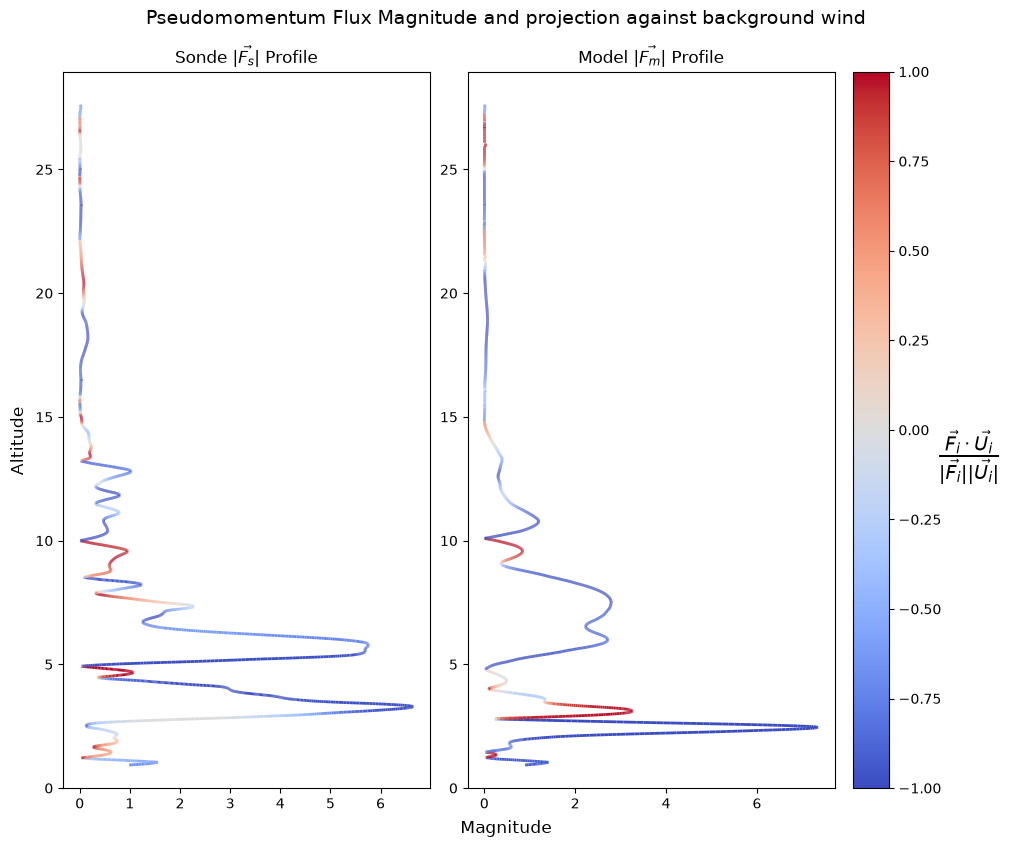

In [16]:
# Idea: The profile itself will show the flux magnitude
# The colour of the profile will show the orientation. 

# Find the dot product between the Flux and horizontal wind vector
F_s = np.column_stack((Flux_u_s, Flux_v_s))
U_s = np.column_stack((u_s_wind_mean, v_s_wind_mean))

F_mag_s = np.linalg.norm(F_s, axis=1)
U_mag_s = np.linalg.norm(U_s, axis=1)

f_u_dot_s = np.sum(F_s * U_s, axis=1) / (F_mag_s * U_mag_s)

# Repeat the dot product calculation for the model sonde
F_m = np.column_stack((Flux_u_m, Flux_v_m))
U_m = np.column_stack((u_m_wind_mean, v_m_wind_mean))

F_mag_m = np.linalg.norm(F_m, axis=1)
U_mag_m = np.linalg.norm(U_m, axis=1)

f_u_dot_m = np.sum(F_m * U_m, axis=1) / (F_mag_m * U_mag_m)


# Construct the plot
fig = plt.figure(figsize=(10, 8), layout="constrained")
ax = fig.subplots(1, 2)

# Set up a norm for coloured profile 
points_s = np.array([F_mag_s, alt_km]).T.reshape(-1,1,2)
norm_s = TwoSlopeNorm(vmin=-1, vmax=1, vcenter=0)
segments_s = np.concatenate([points_s[:-1], points_s[1:]], axis=1)

# Create linecollection and add to plot
lc_s = LineCollection(segments_s, cmap="coolwarm", norm=norm_s, linewidth=2)
lc_s.set_array(f_u_dot_s)
ax[0].add_collection(lc_s)
#cbar_s = fig.colorbar(mappable=lc_s, ax=ax[0])
ax[0].set_title(r"Sonde $|\vec{F_s}|$ Profile")

# Set up a norm for coloured profile 
points_m = np.array([F_mag_m, alt_km]).T.reshape(-1,1,2)
norm_m = TwoSlopeNorm(vmin=-1, vmax=1, vcenter=0)
segments_m = np.concatenate([points_m[:-1], points_m[1:]], axis=1)

# Create linecollection and add to plot
lc_m = LineCollection(segments_m, cmap="coolwarm", norm=norm_m, linewidth=2)
lc_m.set_array(f_u_dot_m)
ax[1].add_collection(lc_m)
cbar_m = fig.colorbar(mappable=lc_m, ax=ax[1])
ax[1].set_title(r"Model $|\vec{F_m}|$ Profile")
cbar_m.set_label(r"$\frac{\vec{F_i} \cdot \vec{U_i}}{|\vec{F_i}| |\vec{U_i}|}$", labelpad=20,rotation=0, fontsize=20)

fig.suptitle(r"Pseudomomentum Flux Magnitude and projection against background wind", fontsize=14, y=1.04)
fig.supylabel("Altitude")
fig.supxlabel("Magnitude")
for i in ax:
    i.set_ylim(0, None)
    i.set_xlim(None, None)

Text(0.5, 0.01, 'Magnitude')

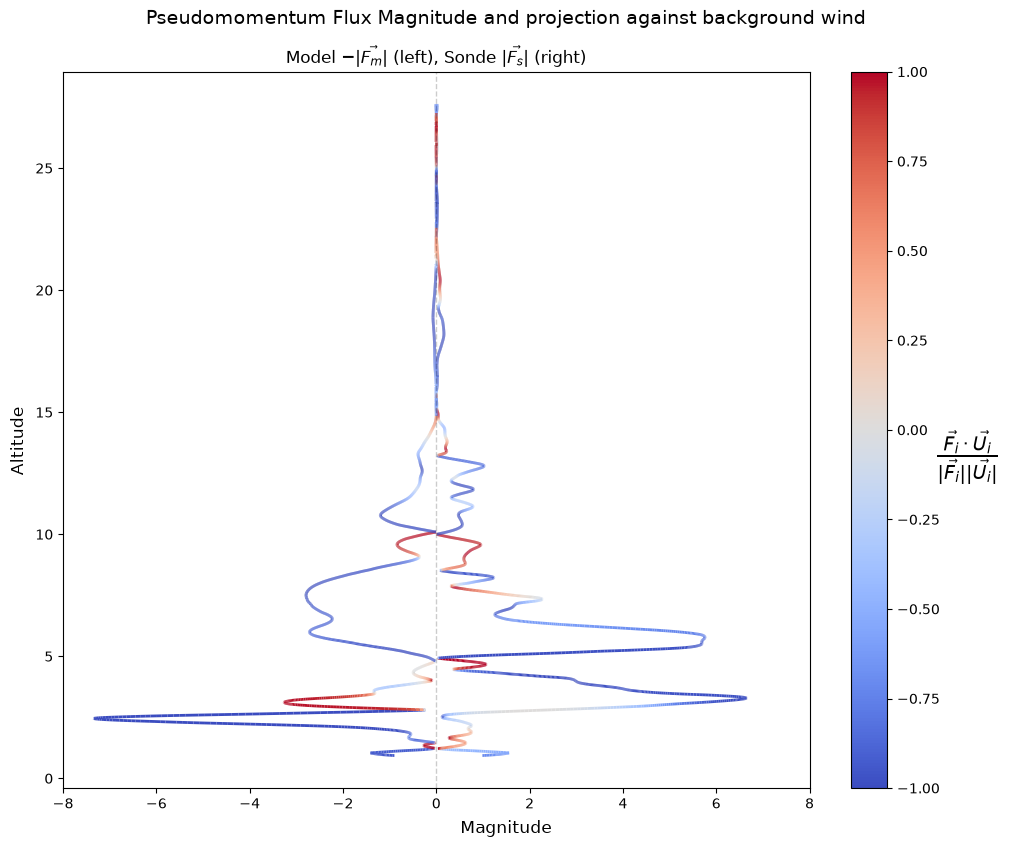

In [28]:
# Construct the plot
fig = plt.figure(figsize=(10, 8), layout="constrained")
ax = fig.subplots(1, 1)

# Set up a norm for coloured profile 
points_s = np.array([F_mag_s, alt_km]).T.reshape(-1,1,2)
norm_s = TwoSlopeNorm(vmin=-1, vmax=1, vcenter=0)
segments_s = np.concatenate([points_s[:-1], points_s[1:]], axis=1)

# Create linecollection and add to plot
lc_s = LineCollection(segments_s, cmap="coolwarm", norm=norm_s, linewidth=2)
lc_s.set_array(f_u_dot_s)
ax.add_collection(lc_s)

# Set up a norm for coloured profile 
points_m = np.array([-F_mag_m, alt_km]).T.reshape(-1,1,2)
norm_m = TwoSlopeNorm(vmin=-1, vmax=1, vcenter=0)
segments_m = np.concatenate([points_m[:-1], points_m[1:]], axis=1)

# Create linecollection and add to plot
lc_m = LineCollection(segments_m, cmap="coolwarm", norm=norm_m, linewidth=2)
lc_m.set_array(f_u_dot_m)
ax.add_collection(lc_m)
cbar_m = fig.colorbar(mappable=lc_m, ax=ax)
ax.set_title(r"Model $-|\vec{F_m}|$ (left), Sonde $|\vec{F_s}|$ (right)")
cbar_m.set_label(r"$\frac{\vec{F_i} \cdot \vec{U_i}}{|\vec{F_i}| |\vec{U_i}|}$", labelpad=20,rotation=0, fontsize=20)

ax.axvline(0, color="k", linewidth=1, linestyle="--", alpha=0.2)

ax.set_xlim(-8, 8)

fig.suptitle(r"Pseudomomentum Flux Magnitude and projection against background wind", fontsize=14, y=1.04)
fig.supylabel("Altitude")
fig.supxlabel("Magnitude")


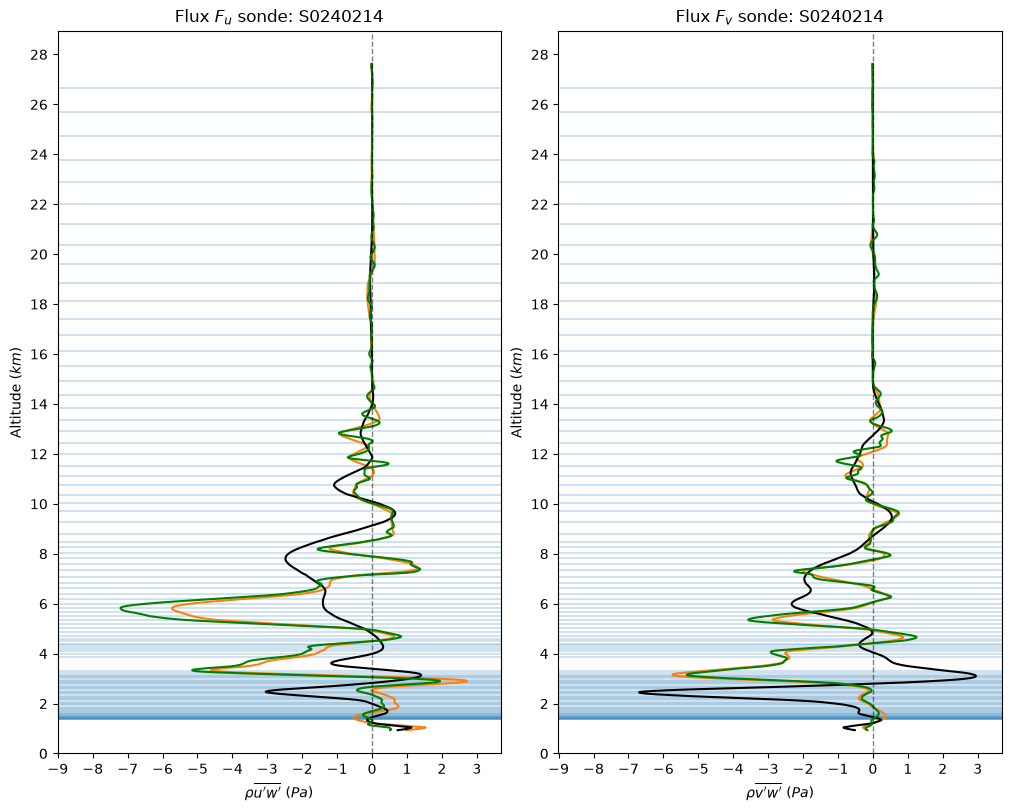

In [11]:
# %%
# Plot the Fluxes
fig = plt.figure(figsize=(10,8), layout="constrained") 
ax = fig.subplots(1,2).flatten()

ylim = (0,None)

max_flux = np.max(np.array([np.max(Flux_u_s), np.max(Flux_u_m), np.max(Flux_u_r), np.max(Flux_v_s), np.max(Flux_v_m), np.max(Flux_v_r)]))
min_flux = np.min(np.array([np.min(Flux_u_s), np.min(Flux_u_m), np.min(Flux_u_r), np.min(Flux_v_s), np.min(Flux_v_m), np.min(Flux_v_r)]))

xlim = (1.25*min_flux, 1.25*max_flux)
#xlim = (-1e-1, 1e-1)

# Plot zonal flux
ax[0].plot(Flux_u_s, alt_km, color="C1")
ax[0].plot(Flux_u_m, alt_km, color="k")
ax[0].plot(Flux_u_r, alt_km, color="green")
ax[0].axvline(0, linestyle="--", linewidth=1, color="k", alpha=0.5)

ax[0].set_xlim(xlim)
ax[0].locator_params(axis="x", nbins=15)
ax[0].set_xlabel(r"$\rho \overline{u^\prime w^\prime}$ ($Pa$)")

ax[0].set_ylim(ylim)
ax[0].locator_params(axis="y", nbins=15)
ax[0].set_ylabel(r"Altitude ($km$)")

ax[0].set_title(rf"Flux $F_u$ sonde: {plot_title_affix}")

#Plot meridional flux
ax[1].plot(Flux_v_s, alt_km, color="C1")
ax[1].plot(Flux_v_m, alt_km, color="k")
ax[1].plot(Flux_v_r, alt_km, color="green")
ax[1].axvline(0, linestyle="--", linewidth=1, color="k", alpha=0.5)

ax[1].set_xlim(xlim)
ax[1].locator_params(axis="x", nbins=15)
ax[1].set_xlabel(r"$\rho \overline{v^\prime w^\prime}$ ($Pa$)")

ax[1].set_ylim(ylim)
ax[1].locator_params(axis="y", nbins=15)
ax[1].set_ylabel(r"Altitude ($km$)")

ax[1].set_title(rf"Flux $F_v$ sonde: {plot_title_affix}")


for height in cross_heights:
    if np.isfinite(height):
        ax[0].axhline(height*1e-3, linewidth=0.3, alpha=1, zorder=1)
        ax[1].axhline(height*1e-3, linewidth=0.3, alpha=1, zorder=1)

plt.show()
#plt.savefig(f"Momentum_flux_sonde_id_{plot_title_affix}.png")



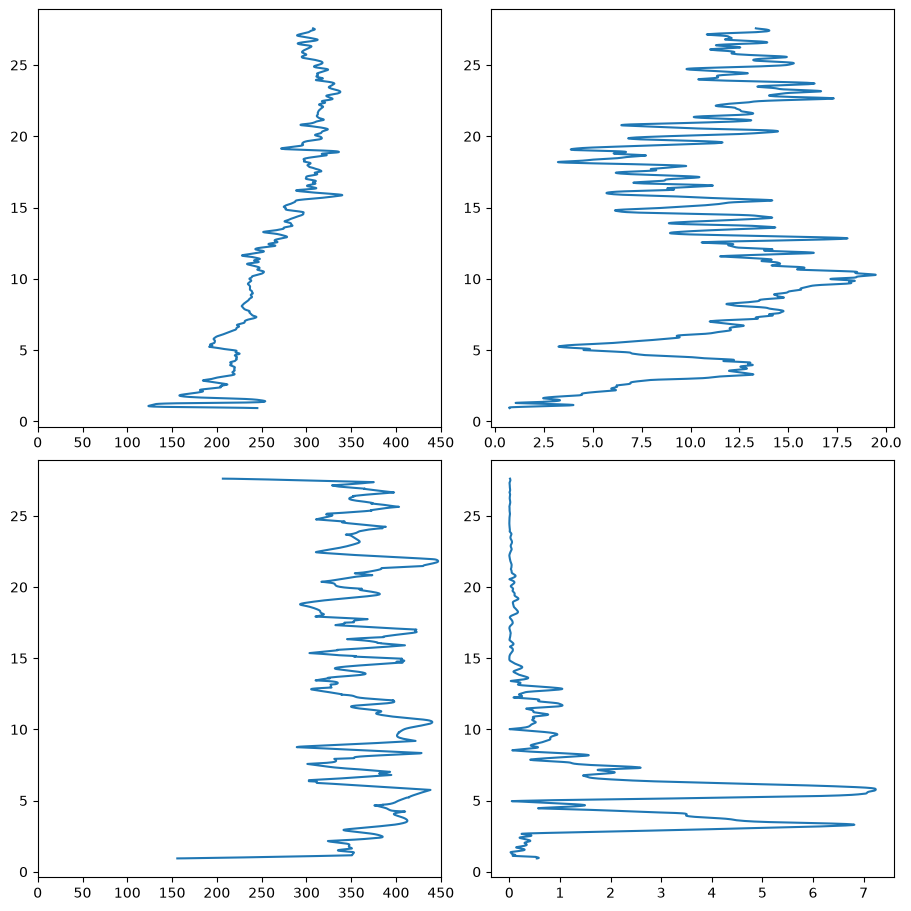

In [12]:
# %%
# Work out a Flux vector

heading = (180/np.pi * np.arctan(Flux_u_r/Flux_v_r)) + 360
Flux_mag = np.sqrt(Flux_u_r**2 + Flux_v_r**2)

heading = tx.rolling_mean(heading, 100)


# %%
# Looking at flux vector and direction
r_cubes = iris.load(cubelist_r_path)

wind_direction_cube = r_cubes.extract_cube("wind_from_direction")
wind_direction_raw = wind_direction_cube.data

wind_mag_cube = r_cubes.extract_cube("wind_speed")
wind_mag_raw = wind_mag_cube.data

# %%
fig = plt.figure(figsize=(9,9), layout="constrained")
ax = fig.subplots(2,2).flatten()

ax[0].plot(wind_direction_raw, alt_km)
ax[0].set_xlim(0, 450)
ax[1].plot(wind_mag_raw, alt_km)
ax[2].plot(heading, alt_km)
ax[2].set_xlim(0, 450)
ax[3].plot(Flux_mag, alt_km)


# %%





In [13]:
# Try to generate vertical profiles for all the sondes
